# SMTG-volcano-plots-all-samples-peptide-label
4.14.25

Create volcano plots for ALL of the samples in the experiment, i.e., not just limiting to a single batch. We're also reporting BH corrected p-values. In other words, this one is the real deal. I'm also using this notebook to generate Venn diagrams of DE peptides. 

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
from adjustText import adjust_text
from matplotlib_venn import venn2, venn2_circles

from scipy.stats import false_discovery_control

import matplotlib.pyplot as plt
import seaborn as sns

# plotting templates
#sns.set(context="paper", style="ticks") 
sns.set(context="talk", style="ticks") 
pal = sns.color_palette("tab10")

#### Configs

In [2]:
nettle_skyline_report_path="../results/SMTG-nettle-norm-report.csv"
gt_report_path="../results/SMTG-unimputed-norm-report.csv"

# Set the thresholds
alpha=0.01
fc_thresh=1.0

#### Functions 

In [3]:
def colmin_impute(lib):
    """
    Imputes missing values with the lowest value quantified for
    any peptide in that run 
    
    Parameters
    ----------
    lib : `pandas`.DataFrame, 
        A dataframe where rows are peptides and columns are
        runs and value are quants. 

    Returns
    ----------
    lib_imp_pd : `pandas`.DataFrame, 
        The imputed dataframe, with the peptide IDs and sample
        names intact. 
    """
    # Get the non-missing column mins
    lib_imp = np.array(lib)
    col_mins = np.nanmin(lib_imp, axis=0)
    
    # Get the indices corresponding to the missing RTs
    nan_idx = np.where(np.isnan(lib_imp))
    
    # For each missing col idx, take the corresponding col min
    lib_imp[nan_idx] = np.take(col_mins, nan_idx[1])

    lib_imp_pd = pd.DataFrame(lib_imp, columns=lib.columns, index=lib.index)
    return lib_imp_pd
    
def rowmean_impute(lib):
    """
    Does a quick row means imputation for a matrix of peptide
    quants. 
    
    Parameters
    ----------
    lib : `pandas`.DataFrame, 
        A dataframe where rows are peptides and columns are
        runs and value are quants. 

    Returns
    ----------
    lib_imp_pd : `pandas`.DataFrame, 
        The imputed dataframe, with the peptide IDs and sample
        names intact. 
    """
    # Get the row means
    lib_imp = np.array(lib)
    row_means = np.nanmean(lib_imp, axis=1)
    
    # Get the indices corresponding to the missing RTs
    nan_idx = np.where(np.isnan(lib_imp))
    
    # For each missing row idx, take the corresponding row mean
    lib_imp[nan_idx] = np.take(row_means, nan_idx[0])

    lib_imp_pd = pd.DataFrame(lib_imp, columns=lib.columns, index=lib.index)
    return lib_imp_pd
    
def bh_procedure(pvals, alpha):
    """
    Performs the Benjamini-Hochberg procedure. We're
    just determining which p-values are significant 
    at the specified alpha. The input has to be a list
    of SORTED p-values. 
    
    Parameters
    ----------
    pvals : np.ndarray, 
        The sorted list of uncorrected p-values. Sorted
        from smallest to largest. 
    alpha : float, 
        The pre-specified alpha value. 

    Returns
    -----------
    keep_bool : boolean list, 
        TRUE if significant at the specified alpha, 
        FALSE if otherwise
    """
    keep_bools = []

    for i in range(0, len(pvals)):
        curr_bool = False
        curr_rank = i + 1
        curr_pval = pvals[i]
        curr_j = (curr_rank * alpha) / len(pvals)

        if curr_pval <= curr_j: 
            curr_bool = True
        keep_bools.append(curr_bool)

    return keep_bools 

def bh_adjustment(pvals):
    """
    Performs the Benjamini-Hochberg ADJUSTMENT. 
    
    Parameters
    ----------
    pvals : np.ndarray, 
        The sorted list of uncorrected p-values. Sorted
        from smallest to largest. 
    Returns
    -----------
    pvals_adj : np.array, 
        The adjusted p-values. 
    """
    pvals_adj = []

    for i in range(0, len(pvals)):
        curr_rank = i + 1
        curr_pval = pvals[i]

        pval_adj = (curr_pval * len(pvals)) / curr_rank 
        pvals_adj.append(pval_adj)

    return pvals_adj

#### Read in the SMTG metadata file 
The TZR samples are from SMTG. The HADT samples are brain QC. 

In [4]:
smtg_metadata = pd.read_csv("../data/smtg-metadata.csv")
#smtg_metadata.head(3)

#### Read in and pre-process the Nettle imputed Skyline quants report 
We want to drop the QC samples (HADTXX) as well. 

In [5]:
todrop = ["Peptide", "Peptide Modified Sequence",
          "chrlib-4mz-ovlp-400to500-Lib-B1 Normalized Area", 
          "chrlib-4mz-ovlp-500to600-Lib-B1 Normalized Area", 
          "chrlib-4mz-ovlp-600to700-Lib-B1 Normalized Area", 
          "chrlib-4mz-ovlp-700to800-Lib-B1 Normalized Area", 
          "chrlib-4mz-ovlp-800to900-Lib-B1 Normalized Area", 
          "chrlib-4mz-ovlp-900to1000-Lib-B1 Normalized Area", 
          "B1-ind-8mz-ovlp-400to1000-HADT01 Normalized Area", 
          "B2-ind-8mz-ovlp-400to1000-HADT02 Normalized Area", 
          "B3-ind-8mz-ovlp-400to1000-HADT03 Normalized Area", 
          "B4-5-ind-8mz-ovlp-400to1000-HADT04 Normalized Area", 
          "B4-5-ind-8mz-ovlp-400to1000-HADTP05 Normalized Area"]

nettle_mat = pd.read_csv(nettle_skyline_report_path)
nettle_mat = nettle_mat[nettle_mat["Protein"] != "Decoys"]

nettle_mat.index = nettle_mat["Peptide Modified Sequence"]
nettle_mat = nettle_mat.drop(columns=todrop)

#### Read in the unimputed ground truth Skyline report 

In [6]:
gt_mat = pd.read_csv(gt_report_path)
gt_mat = gt_mat[gt_mat["Protein"] != "Decoys"]

gt_mat.index=gt_mat["Peptide Modified Sequence"]
gt_mat = gt_mat.drop(columns=todrop)

#gt_mat.head(3)
print(nettle_mat.shape)
print(gt_mat.shape)

(107555, 69)
(107555, 69)


#### Isolate the protein IDs

In [7]:
prot_ids_nettle = []
for x in list(nettle_mat["Protein Name"]):
    y = x.split("|")[2]
    z = y.split("_")[0]
    prot_ids_nettle.append(z)

prot_ids_unimputed = []
for x in list(gt_mat["Protein Name"]):
    y = x.split("|")[2]
    z = y.split("_")[0]
    prot_ids_unimputed.append(z)

nettle_mat = nettle_mat.drop(columns=["Protein Name", "Protein"])
gt_mat = gt_mat.drop(columns=["Protein Name", "Protein"])

#### Get rid of the "normalized quant" part of the column ID

In [8]:
new_col_ids = [x.split(" ")[0] for x in nettle_mat.columns]
nettle_mat.columns = new_col_ids

new_col_ids = [x.split(" ")[0] for x in gt_mat.columns]
gt_mat.columns = new_col_ids

#### Isolate just the sample ID from the column names
For both matrices. 

In [9]:
# Isolate just the sample ID from the column name
new_colnames = [x.split("-")[-1] for x in nettle_mat.columns]
nettle_mat.columns = new_colnames

# Isolate just the sample ID from the column name
new_colnames1 = [x.split("-")[-1] for x in gt_mat.columns]
gt_mat.columns = new_colnames1

#### Low value impute the unimputed matrix
I'm curious to see how this changes things. Maybe this is supplemental and main text is the unimputed version? 

In [10]:
# Should these be set to zero or one? 
nettle_mat[nettle_mat == 0] = np.nan
gt_mat[gt_mat == 0] = np.nan

#gt_mat = rowmean_impute(gt_mat)
#gt_mat = colmin_impute(gt_mat)

#### Log the quants
I think for now this should be done **after** low value imputation. 

In [11]:
nettle_mat = np.log(nettle_mat)
gt_mat = np.log(gt_mat)

#### Get the sample IDs corresponding to each condition

In [12]:
meta_add = smtg_metadata[smtg_metadata["Condition"] == "Autosomal Dominant ADD"]
add_sample_ids = list(meta_add["Sample Label"])

meta_sporadic = smtg_metadata[smtg_metadata["Condition"] == "Sporadic ADD"]
sporadic_sample_ids = list(meta_sporadic["Sample Label"])

meta_hcf_low = smtg_metadata[smtg_metadata["Condition"] == "HCF/Low ADNC"]
hcf_low_sample_ids = list(meta_hcf_low["Sample Label"])

meta_hcf_high = smtg_metadata[smtg_metadata["Condition"] == "HCF/High ADNC"]
hcf_high_sample_ids = list(meta_hcf_high["Sample Label"])

print(f"Autosomal Dominant ADD: {len(add_sample_ids)}")
print(f"Sporadic ADD: {len(sporadic_sample_ids)}")
print(f"HCF/Low ADNC: {len(hcf_low_sample_ids)}")
print(f"HCF/High ADNC: {len(hcf_high_sample_ids)}")

Autosomal Dominant ADD: 24
Sporadic ADD: 18
HCF/Low ADNC: 9
HCF/High ADNC: 11


#### Isolate quants matrices for each of the four conditions

In [13]:
# FOR THE NETTLE QUANTS MATRIX
add_nettle_mat = nettle_mat[add_sample_ids]
sporadic_nettle_mat = nettle_mat[sporadic_sample_ids]
hcf_low_nettle_mat = nettle_mat[hcf_low_sample_ids]
hcf_high_nettle_mat = nettle_mat[hcf_high_sample_ids]

add_nettle = np.array(add_nettle_mat)
sporadic_nettle = np.array(sporadic_nettle_mat)
hcf_low_nettle = np.array(hcf_low_nettle_mat)
hcf_high_nettle = np.array(hcf_high_nettle_mat)

# FOR THE GROUND TRUTH QUANTS MATRIX 
add_gt_mat = gt_mat[add_sample_ids]
sporadic_gt_mat = gt_mat[sporadic_sample_ids]
hcf_low_gt_mat = gt_mat[hcf_low_sample_ids]
hcf_high_gt_mat = gt_mat[hcf_high_sample_ids]

add_gt = np.array(add_gt_mat)
sporadic_gt = np.array(sporadic_gt_mat)
hcf_low_gt = np.array(hcf_low_gt_mat)
hcf_high_gt = np.array(hcf_high_gt_mat)

#### Calculate the t-test statistics -- Nettle

In [14]:
pvals = []
rs_stats = []

for i in range(0, add_nettle.shape[0]):
    stat, pval = stats.ttest_ind(add_nettle[i], hcf_low_nettle[i], nan_policy="omit")
    pvals.append(pval)
    rs_stats.append(stat)

# Set any NaN pvals to 1.0
pvals_updated = []
for curr_p in pvals:
    new_p = curr_p
    if np.isnan(curr_p):
        new_p = 1.0
    pvals_updated.append(new_p)
        
# Init a dataframe to hold the p-values and adjusted p-values
nettle_stats = pd.DataFrame(columns = ["Peptide", "pval", "orig_idx"])
nettle_stats["Peptide"] = list(add_nettle_mat.index)
nettle_stats["Protein"] = prot_ids_nettle
nettle_stats["pval"] = pvals_updated

/net/noble/vol2/home/lincolnh/miniconda3/envs/deep-impute/lib/python3.9/site-packages/scipy/stats/_stats_py.py:6951: RuntimeWarning: invalid value encountered in scalar divide
  svar = ((n1 - 1) * v1 + (n2 - 1) * v2) / df


#### Calculate the t-test statistics -- Ground Truth 

In [15]:
pvals1 = []
rs_stats1 = []

for i in range(0, add_gt.shape[0]):
    stat, pval = stats.ttest_ind(add_gt[i], hcf_low_gt[i], nan_policy="omit")
    pvals1.append(pval)
    rs_stats1.append(stat)

# Set any NaN pvals to 1.0
pvals1_updated = []
for curr_p in pvals1:
    new_p = curr_p
    if np.isnan(curr_p):
        new_p = 1.0
    pvals1_updated.append(new_p)

# Init a dataframe to hold the p-values and adjusted p-values
gt_stats = pd.DataFrame(columns = ["Peptide", "pval", "orig_idx"])
gt_stats["Peptide"] = list(add_gt_mat.index)
gt_stats["Protein"] = prot_ids_unimputed
gt_stats["pval"] = pvals1_updated

/net/noble/vol2/home/lincolnh/miniconda3/envs/deep-impute/lib/python3.9/site-packages/scipy/stats/_stats_py.py:6951: RuntimeWarning: invalid value encountered in scalar divide
  svar = ((n1 - 1) * v1 + (n2 - 1) * v2) / df


#### Do the Benjamini-Hochberg procedure -- Nettle

In [16]:
# Sort by raw p-values
nettle_stats = nettle_stats.sort_values(by="pval", ascending=True)

# Run the BH procedure/adjustment
pvals_adj = false_discovery_control(np.array(nettle_stats["pval"]), method="bh")
nettle_stats["pval-adj"] = pvals_adj

# Return to the original order
#   Do we really need this? 
nettle_stats["orig_idx"] = list(nettle_stats.index)
nettle_stats = nettle_stats.sort_values(by="orig_idx")

#### Do the Benjamini-Hochberg procedure -- Ground Truth

In [17]:
# Sort by raw p-values
gt_stats = gt_stats.sort_values(by="pval", ascending=True)

# Run the BH procedure/adjustment
pvals_adj1 = false_discovery_control(np.array(gt_stats["pval"]), method="bh")
gt_stats["pval-adj"] = pvals_adj1

# Return to the original order
gt_stats["orig_idx"] = list(gt_stats.index)
gt_stats = gt_stats.sort_values(by="orig_idx")

#### Get the log fold changes -- Nettle

In [18]:
# Exponentiate so that we can properly get the log fold changes
add_nettle_exp = np.exp(add_nettle)
hcf_low_nettle_exp = np.exp(hcf_low_nettle)

add_means = np.nanmean(add_nettle_exp, axis=1)
hcf_low_means = np.nanmean(hcf_low_nettle_exp, axis=1)

fc_nettle = np.log2(add_means / hcf_low_means)

fdr_nettle = -np.log10(np.array(nettle_stats["pval-adj"]))

/tmp/ipykernel_1861967/335309856.py:5: RuntimeWarning: Mean of empty slice
  add_means = np.nanmean(add_nettle_exp, axis=1)
/tmp/ipykernel_1861967/335309856.py:6: RuntimeWarning: Mean of empty slice
  hcf_low_means = np.nanmean(hcf_low_nettle_exp, axis=1)


#### Get the log fold changes -- Ground Truth 

In [19]:
# Exponentiate so that we can properly get the log fold changes
add_gt_exp = np.exp(add_gt)
hcf_low_gt_exp = np.exp(hcf_low_gt)

add_means1 = np.nanmean(add_gt_exp, axis=1)
hcf_low_means1 = np.nanmean(hcf_low_gt_exp, axis=1)

fc_gt = np.log2(add_means1 / hcf_low_means1)

fdr_gt = -np.log10(np.array(gt_stats["pval-adj"]))

/tmp/ipykernel_1861967/2170244089.py:5: RuntimeWarning: Mean of empty slice
  add_means1 = np.nanmean(add_gt_exp, axis=1)
/tmp/ipykernel_1861967/2170244089.py:6: RuntimeWarning: Mean of empty slice
  hcf_low_means1 = np.nanmean(hcf_low_gt_exp, axis=1)


#### Create an aggregated dataframe -- Nettle

In [20]:
nettle_res = pd.DataFrame(columns=["Peptide", "Protein", "pval", "FC"])
nettle_res["Peptide"] = nettle_stats["Peptide"]
nettle_res["Protein"] = nettle_stats["Protein"]
nettle_res["pval"] = np.array(nettle_stats["pval"])
nettle_res["pval-adj"] = np.array(nettle_stats["pval-adj"])
nettle_res["FC"] = fc_nettle
nettle_res["FDR"] = fdr_nettle

nettle_res.head(3)

,Peptide,Protein,pval,FC,pval-adj,FDR
0,VHIPDLSSFAMPLLDGDLEGSGK,AAKG2,0.004721,-0.465534,0.079273,1.100877
1,TVFPFSYQESPPR,AAKG2,0.980191,0.124553,1.000000,-0.000000
2,MSFSGIFR,AAKG2,0.402079,-0.091967,0.745100,0.127786


#### Create an aggregated dataframe -- Ground Truth 

In [21]:
gt_res = pd.DataFrame(columns=["Peptide", "Protein", "pval", "FC"])
gt_res["Peptide"] = gt_stats["Peptide"]
gt_res["Protein"] = gt_stats["Protein"]
gt_res["pval"] = np.array(gt_stats["pval"])
gt_res["pval-adj"] = np.array(gt_stats["pval-adj"])
gt_res["FC"] = fc_gt
gt_res["FDR"] = fdr_gt

gt_res.head(3)

,Peptide,Protein,pval,FC,pval-adj,FDR
0,VHIPDLSSFAMPLLDGDLEGSGK,AAKG2,1.000000,NaN,1.0,-0.0
1,TVFPFSYQESPPR,AAKG2,0.976156,0.169541,1.0,-0.0
2,MSFSGIFR,AAKG2,0.914630,0.075501,1.0,-0.0


#### Define DE peptides -- Nettle
According to pre-established values. 

In [22]:
nettle_up_df = nettle_res[(nettle_res["pval-adj"] < alpha) & (nettle_res["FC"] >= fc_thresh)]
nettle_down_df = nettle_res[(nettle_res["pval-adj"] < alpha) & (nettle_res["FC"] <= -fc_thresh)]

nettle_up_df = nettle_up_df.sort_values(by="pval-adj", ascending=True)
nettle_down_df = nettle_down_df.sort_values(by="pval-adj", ascending=True)

print(f"num up-reg: {nettle_up_df.shape[0]}")
print(f"num down-reg: {nettle_down_df.shape[0]}")

num up-reg: 406
num down-reg: 111


#### Define DE peptides -- Ground Truth 

In [23]:
gt_up_df = gt_res[(gt_res["pval-adj"] < alpha) & (gt_res["FC"] >= fc_thresh)]
gt_down_df = gt_res[(gt_res["pval-adj"] < alpha) & (gt_res["FC"] <= -fc_thresh)]

gt_up_df = gt_up_df.sort_values(by="pval-adj", ascending=True)
gt_down_df = gt_down_df.sort_values(by="pval-adj", ascending=True)

print(f"num up-reg: {gt_up_df.shape[0]}")
print(f"num down-reg: {gt_down_df.shape[0]}")

num up-reg: 251
num down-reg: 89


#### Replace some of the peptide IDs -- unimputed

In [24]:
# THE UP-REGULATED DATAFRAME
gt_up_df.reset_index(drop=True, inplace=True)
prots = list(gt_up_df["Protein"])

new_prots = []
for curr in prots:
    if curr == "MK":
        curr = "MDK"
    elif curr == "COPA1":
        curr = "COL25A1"
    elif curr == "A4":
        curr = "APP"
    new_prots.append(curr)

gt_up_df["Protein"] = new_prots

# THE DOWN-REGULATED DATAFRAME
gt_down_df.reset_index(drop=True, inplace=True)
prots = list(gt_down_df["Protein"])

new_prots = []
for curr in prots:
    if curr == "MK":
        curr = "MDK"
    elif curr == "COPA1":
        curr = "COL25A1"
    elif curr == "A4":
        curr = "APP"
    new_prots.append(curr)

gt_down_df["Protein"] = new_prots

#### Replace a couple of the peptide IDs -- Nettle 

In [25]:
# THE UP-REGULATED DATAFRAME
nettle_up_df.reset_index(drop=True, inplace=True)
prots = list(nettle_up_df["Protein"])

new_prots = []
for curr in prots:
    if curr == "MK":
        curr = "MDK"
    elif curr == "COPA1":
        curr = "COL25A1"
    elif curr == "A4":
        curr = "APP"
    new_prots.append(curr)

nettle_up_df["Protein"] = new_prots

# THE DOWN-REGULATED DATAFRAME
nettle_down_df.reset_index(drop=True, inplace=True)
prots = list(nettle_down_df["Protein"])

new_prots = []
for curr in prots:
    if curr == "MK":
        curr = "MDK"
    elif curr == "COPA1":
        curr = "COL25A1"
    elif curr == "A4":
        curr = "APP"
    new_prots.append(curr)

nettle_down_df["Protein"] = new_prots

#### Get the unimputed volcano plot

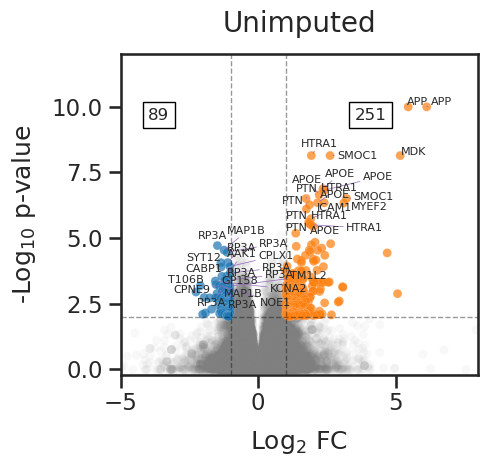

In [26]:
fig, ax = plt.subplots(figsize=(5,5))

# Get the base scatter plot
sns.scatterplot(
    data=gt_res,
    x="FC", 
    y="FDR", 
    alpha=0.05, 
    linewidth=0.1,
    color="#7f7f7f",
    rasterized=True,
    size=0.5,
    legend=False,
)
# Add the up-regulated proteins
sns.scatterplot(
    data=gt_up_df,
    x="FC", 
    y="FDR", 
    alpha=0.7, 
    linewidth=0.1,
    color="#ff7f0e",
    rasterized=False,
    size=0.5,
    legend=False,
)
# Add the down-regulated proteins
sns.scatterplot(
    data=gt_down_df,
    x="FC", 
    y="FDR", 
    alpha=0.7, 
    linewidth=0.1,
    color="#1f77b4",
    rasterized=False,
    size=0.5,
    legend=False,
)
ax.set_title("Unimputed", pad=16, size=20)
ax.set_xlabel("Log$_{2}$ FC", labelpad=10)
ax.set_ylabel("-Log$_{10}$ p-value", labelpad=10)

ax.axvline(fc_thresh ,color="black", linestyle="--", alpha=0.4, lw=1.0)
ax.axvline(-fc_thresh ,color="black", linestyle="--", alpha=0.4, lw=1.0)
ax.axhline(-np.log10(alpha), color="black", linestyle="--", alpha=0.4, lw=1.0)

ax.set_xlim(-5, 8)
ax.set_ylim(-0.2, 12)

ax.text(x=-4, y=9.5, s=gt_down_df.shape[0], fontsize=12, bbox=dict(facecolor="none", edgecolor="black", lw=1))
ax.text(x=3.5, y=9.5, s=gt_up_df.shape[0], fontsize=12, bbox=dict(facecolor="none", edgecolor="black", lw=1))

# Add labels for the up-regulated proteins
labels = []
for idx, row in gt_up_df[:20].iterrows():
    x_coord = row["FC"]
    y_coord = row["FDR"]
    labels.append(ax.text(x_coord, y_coord, s=row["Protein"], fontsize=8))

# Add labels for the down-regulated proteins
for idx, row in gt_down_df[:20].iterrows():
    x_coord = row["FC"]
    y_coord = row["FDR"]
    labels.append(ax.text(x_coord, y_coord, s=row["Protein"], fontsize=8))
adjust_text(labels, arrowprops=dict(arrowstyle='-', lw=0.5, color="#9467bd"),
           ensure_inside_axes=True, expand_axes=False)

plt.tight_layout()
#plt.show()
#plt.savefig("../figures/add-v-control-volcano-unimputed.png", dpi=350, bbox_inches="tight")
#plt.savefig("../figures/add-v-control-all-samples-volcano-unimputed.pdf", bbox_inches="tight")

#### For Nettle imputed

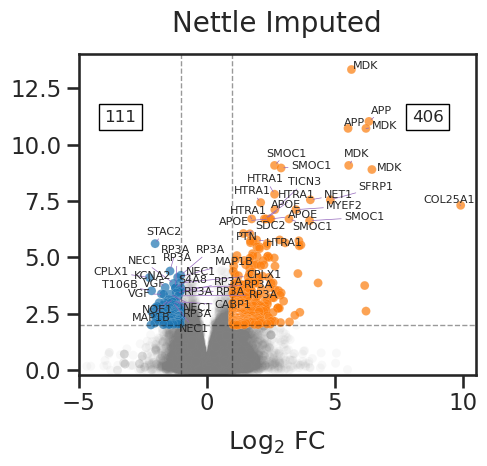

In [27]:
fig, ax = plt.subplots(figsize=(5,5))

# Get the base scatter plot
sns.scatterplot(
    data=nettle_res,
    x="FC", 
    y="FDR", 
    alpha=0.05, 
    linewidth=0.1,
    color="#7f7f7f",
    rasterized=True,
    size=0.5,
    legend=False,
)
# Add the up-regulated proteins
sns.scatterplot(
    data=nettle_up_df,
    x="FC", 
    y="FDR", 
    alpha=0.7, 
    linewidth=0.1,
    color="#ff7f0e",
    rasterized=False,
    size=0.5,
    legend=False,
)
# Add the down-regulated proteins
sns.scatterplot(
    data=nettle_down_df,
    x="FC", 
    y="FDR", 
    alpha=0.7, 
    linewidth=0.1,
    color="#1f77b4",
    rasterized=False,
    size=0.5,
    legend=False,
)

ax.set_title("Nettle Imputed", pad=16, size=20)
ax.set_xlabel("Log$_{2}$ FC", labelpad=10)
ax.set_ylabel("")

ax.axvline(fc_thresh ,color="black", linestyle="--", alpha=0.4, lw=1.0)
ax.axvline(-fc_thresh ,color="black", linestyle="--", alpha=0.4, lw=1.0)
ax.axhline(-np.log10(alpha), color="black", linestyle="--", alpha=0.4, lw=1.0)

ax.set_xlim(-5, 10.5)
ax.set_ylim(-0.2, 14)

ax.text(x=-4, y=11, s=nettle_down_df.shape[0], fontsize=12, 
           bbox=dict(facecolor="none", edgecolor="black", lw=1))
ax.text(x=8, y=11, s=nettle_up_df.shape[0], fontsize=12, 
           bbox=dict(facecolor="none", edgecolor="black", lw=1))

# Add labels for the up-regulated proteins
labels = []
for idx, row in nettle_up_df[:25].iterrows():
    x_coord = row["FC"]
    y_coord = row["FDR"]
    labels.append(ax.text(x_coord, y_coord, s=row["Protein"], fontsize=8))

# Add labels for the down-regulated proteins
for idx, row in nettle_down_df[:25].iterrows():
    x_coord = row["FC"]
    y_coord = row["FDR"]
    labels.append(ax.text(x_coord, y_coord, s=row["Protein"], fontsize=8))
adjust_text(labels, arrowprops=dict(arrowstyle='-', lw=0.5, color="#9467bd"),
           ensure_inside_axes=True, expand_axes=False)

plt.tight_layout()
#plt.show()
#plt.savefig("../figures/add-v-control-all-samples-volcano-nettle.png", dpi=250, bbox_inches="tight")
#plt.savefig("../figures/add-v-control-all-samples-volcano-nettle.pdf", bbox_inches="tight")

#### Zoom in on APP 
LVFFAEDVGSNK is the ADD indicator, control samples should have HDSGYEVHHQK. 

In [28]:
nettle_up_df[nettle_up_df["Protein"] == "APP"]
#nettle_down_df[nettle_down_df["Protein"] == "APP"]

#gt_up_df[gt_up_df["Protein"] == "APP"]
#gt_down_df[gt_down_df["Protein"] == "APP"]

,Peptide,Protein,pval,FC,pval-adj,FDR
1,LVFFAEDVGSNK,APP,1.760059e-16,6.328095,9.465157e-12,11.023872
2,HDSGYEVHHQK,APP,7.131547e-16,5.512400,1.930334e-11,10.714368


#### Zoom in on APOE
wildtype peptide is LGADMEDV**C**GR. APOE4 (high predictive of ADD) is LGADMEDV**R**GR. 

In [29]:
nettle_up_df[nettle_up_df["Protein"] == "APOE"]
#nettle_down_df[nettle_down_df["Protein"] == "APOE"]

#gt_up_df[gt_up_df["Protein"] == "APOE"]
#gt_down_df[gt_down_df["Protein"] == "APOE"]

,Peptide,Protein,pval,FC,pval-adj,FDR
16,LEEQAQQIR,APOE,3.730038e-11,2.453331,1.976498e-07,6.704104
17,LQAEAFQAR,APOE,3.713066e-11,2.309476,1.976498e-07,6.704104
20,MEEMGSR,APOE,3.859092e-11,2.501686,1.976498e-07,6.704104
31,AQAWGER,APOE,7.113095e-10,2.363637,2.390778e-06,5.621461
35,QWAGLVEK,APOE,1.196512e-09,2.050775,3.386603e-06,5.470236
49,AATVGSLAGQPLQER,APOE,6.673952e-09,1.461346,1.380417e-05,4.859990
51,SWFEPLVEDMQR,APOE,9.949632e-09,1.954824,1.981727e-05,4.702956
87,ELQAAQAR,APOE,1.760529e-07,1.403486,1.660998e-04,3.779631
88,GEVQAMLGQSTEELR,APOE,1.838458e-07,1.447601,1.704615e-04,3.768374
112,DADDLQK,APOE,5.758901e-07,1.660947,3.622214e-04,3.441026


---
## Can we use colors to indicate subset? 
On the volcano plots? Where subsets are: Nettle only, unimputed only, shared, neither. 

#### Get the shared vs unique peptides, up-regulated

In [30]:
shared_peptides = np.intersect1d(np.array(gt_up_df["Peptide"]), 
                                 np.array(nettle_up_df["Peptide"]))
shared_idx0 = [x in shared_peptides for x in list(nettle_up_df["Peptide"])]
shared_idx1 = [x in shared_peptides for x in list(gt_up_df["Peptide"])]

# Get the Nettle unique peptides (up-regulated)
nettle_up_unique = nettle_up_df[~np.array(shared_idx0)]
nettle_up_unique = nettle_up_unique.reset_index(drop=True)

# Get the unimputed unique peptides (up-regulated)
gt_up_unique = gt_up_df[~np.array(shared_idx1)]
gt_up_unique = gt_up_unique.reset_index(drop=True)

# Get the Nettle shared peptides
nettle_up_shared = nettle_up_df[shared_idx0]
nettle_up_shared = nettle_up_shared.reset_index(drop=True)

# Get the Nettle shared peptides 
gt_up_shared = gt_up_df[shared_idx1]
gt_up_shared = gt_up_shared.reset_index(drop=True)

#### Repeat, for the down-regulated peptides

In [31]:
shared_peptides = np.intersect1d(np.array(gt_down_df["Peptide"]), 
                                 np.array(nettle_down_df["Peptide"]))
shared_idx0 = [x in shared_peptides for x in list(nettle_down_df["Peptide"])]
shared_idx1 = [x in shared_peptides for x in list(gt_down_df["Peptide"])]

# Get the Nettle unique peptides (down-regulated)
nettle_down_unique = nettle_down_df[~np.array(shared_idx0)]
nettle_down_unique = nettle_down_unique.reset_index(drop=True)

# Get the unimputed unique peptides (down-regulated)
gt_down_unique = gt_down_df[~np.array(shared_idx1)]
gt_down_unique = gt_down_unique.reset_index(drop=True)

# Get the Nettle shared peptides
nettle_down_shared = nettle_down_df[shared_idx0]
nettle_down_shared = nettle_down_shared.reset_index(drop=True)

# Get the Nettle shared peptides 
gt_down_shared = gt_down_df[shared_idx1]
gt_down_shared = gt_down_shared.reset_index(drop=True)

#### Plot

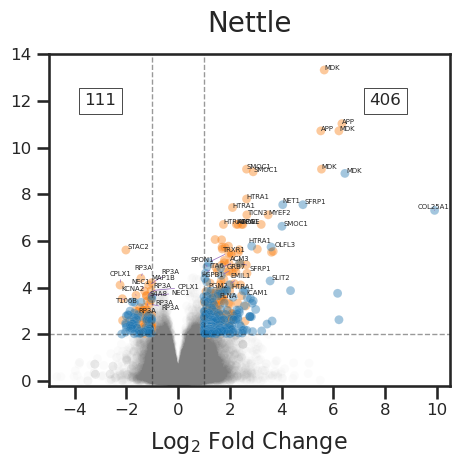

In [41]:
fig, ax = plt.subplots(figsize=(5,5))

# THE BASE SCATTER PLOT
sns.scatterplot(
    data=nettle_res,
    x="FC", 
    y="FDR", 
    alpha=0.025, 
    linewidth=0.025,
    color="#7f7f7f",
    rasterized=True,
    size=0.5,
    legend=False,
)
# THE SHARED UP-REGULATED PEPTIDES
sns.scatterplot(
    data=nettle_up_shared,
    x="FC", 
    y="FDR", 
    alpha=0.4, 
    linewidth=0.1,
    color="#ff7f0e",
    rasterized=False,
    size=0.5,
    legend=False,
    label="Shared",
)
# THE NETTLE UNIQUE UP-REGULATED PEPTIDES
sns.scatterplot(
    data=nettle_up_unique,
    x="FC", 
    y="FDR", 
    alpha=0.4, 
    linewidth=0.1,
    color="#1f77b4",
    rasterized=False,
    size=0.5,
    legend=False,
    label="Unique"
)
# THE SHARED DOWN-REGULATED PEPTIDES 
sns.scatterplot(
    data=nettle_down_shared,
    x="FC", 
    y="FDR", 
    alpha=0.4, 
    linewidth=0.1,
    color="#ff7f0e",
    rasterized=False,
    size=0.5,
    legend=False,
)
# THE NETTLE UNIQUE DOWN-REGULATED PEPTIDES 
sns.scatterplot(
    data=nettle_down_unique,
    x="FC", 
    y="FDR", 
    alpha=0.4, 
    linewidth=0.1,
    color="#1f77b4",
    rasterized=False,
    size=0.5,
    legend=False,
)
ax.set_title("Nettle", pad=16, size=20)
ax.set_xlabel("Log$_{2}$ Fold Change", size=16, labelpad=8)
#ax.set_ylabel("-Log$_{10}$ p-value", size=16, labelpad=8)
ax.set_ylabel("")

ax.axvline(fc_thresh ,color="black", linestyle="--", alpha=0.4, lw=1.0)
ax.axvline(-fc_thresh ,color="black", linestyle="--", alpha=0.4, lw=1.0)
ax.axhline(-np.log10(alpha), color="black", linestyle="--", alpha=0.4, lw=1.0)

ax.set_xlim(-5, 10.5)
ax.set_ylim(-0.2, 14)

ax.tick_params(axis='both', which='major', labelsize=12)

ax.text(x=-3, y=12, s=nettle_down_df.shape[0], fontsize=12, 
        bbox=dict(facecolor="none", edgecolor="black", lw=0.5), 
        ha="center", va="center")
ax.text(x=8, y=12, s=nettle_up_df.shape[0], fontsize=12, 
        bbox=dict(facecolor="none", edgecolor="black", lw=0.5), 
        ha="center", va="center")

# Add labels for the up-regulated shared peptides 
labels = []
for idx, row in nettle_up_shared[:15].iterrows():
    x_coord = row["FC"]
    y_coord = row["FDR"]
    labels.append(ax.text(x_coord, y_coord, s=row["Protein"], fontsize=5))
    
# Add labels for the up-regulated Nettle unique peptides
labels = []
for idx, row in nettle_up_unique[:20].iterrows():
    x_coord = row["FC"]
    y_coord = row["FDR"]
    labels.append(ax.text(x_coord, y_coord, s=row["Protein"], fontsize=5))

# Add labels for the down-regulated proteins
for idx, row in nettle_down_shared[:15].iterrows():
    x_coord = row["FC"]
    y_coord = row["FDR"]
    labels.append(ax.text(x_coord, y_coord, s=row["Protein"], fontsize=5))
adjust_text(labels, arrowprops=dict(arrowstyle='-', lw=0.5, color="#9467bd"),
           ensure_inside_axes=True, expand_axes=False)

# leg = plt.legend( 
#             edgecolor="black", 
#             prop={"size":11}, 
#             bbox_to_anchor=(1.021, 1.022),
# )

plt.tight_layout()
#plt.show()
#plt.savefig("../figures/nettle-color-by-unique.pdf", bbox_inches="tight")

#### Repeat for unimputed 

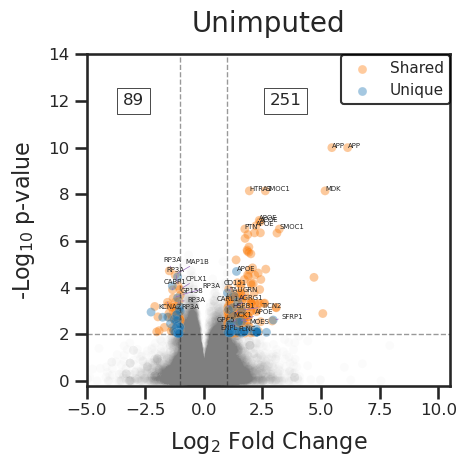

In [42]:
fig, ax = plt.subplots(figsize=(5,5))

# THE BASE SCATTER PLOT
sns.scatterplot(
    data=gt_res,
    x="FC", 
    y="FDR", 
    alpha=0.025, 
    linewidth=0.025,
    color="#7f7f7f",
    rasterized=True,
    size=0.5,
    legend=False,
)
# THE SHARED UP-REGULATED PEPTIDES
sns.scatterplot(
    data=gt_up_shared,
    x="FC", 
    y="FDR", 
    alpha=0.4, 
    linewidth=0.1,
    color="#ff7f0e",
    rasterized=False,
    size=0.5,
    legend=False,
    label="Shared",
)
# THE UNIMPUTED UNIQUE UP-REGULATED PEPTIDES
sns.scatterplot(
    data=gt_up_unique,
    x="FC", 
    y="FDR", 
    alpha=0.4, 
    linewidth=0.1,
    color="#1f77b4",
    rasterized=False,
    size=0.5,
    legend=False,
    label="Unique"
)
# THE SHARED DOWN-REGULATED PEPTIDES 
sns.scatterplot(
    data=gt_down_shared,
    x="FC", 
    y="FDR", 
    alpha=0.4, 
    linewidth=0.1,
    color="#ff7f0e",
    rasterized=False,
    size=0.5,
    legend=False,
)
# THE UNIMPUTED UNIQUE DOWN-REGULATED PEPTIDES 
sns.scatterplot(
    data=gt_down_unique,
    x="FC", 
    y="FDR", 
    alpha=0.4, 
    linewidth=0.1,
    color="#1f77b4",
    rasterized=False,
    size=0.5,
    legend=False,
)
ax.set_title("Unimputed", pad=16, size=20)
ax.set_xlabel("Log$_{2}$ Fold Change", size=16, labelpad=8)
ax.set_ylabel("-Log$_{10}$ p-value", size=16, labelpad=8)

ax.axvline(fc_thresh ,color="black", linestyle="--", alpha=0.4, lw=1.0)
ax.axvline(-fc_thresh ,color="black", linestyle="--", alpha=0.4, lw=1.0)
ax.axhline(-np.log10(alpha), color="black", linestyle="--", alpha=0.4, lw=1.0)

ax.set_xlim(-5, 10.5)
ax.set_ylim(-0.2, 14)

ax.tick_params(axis='both', which='major', labelsize=12)

ax.text(x=-3, y=12, s=gt_down_df.shape[0], fontsize=12, 
        bbox=dict(facecolor="none", edgecolor="black", lw=0.5),
        ha="center", va="center")
ax.text(x=3.5, y=12, s=gt_up_df.shape[0], fontsize=12, 
        bbox=dict(facecolor="none", edgecolor="black", lw=0.5),
        ha="center", va="center")

# Add labels for the up-regulated shared peptides 
labels = []
for idx, row in gt_up_shared[:10].iterrows():
    x_coord = row["FC"]
    y_coord = row["FDR"]
    labels.append(ax.text(x_coord, y_coord, s=row["Protein"], fontsize=5))
    
# Add labels for the up-regulated unimputed unique peptides
labels = []
for idx, row in gt_up_unique[:15].iterrows():
    x_coord = row["FC"]
    y_coord = row["FDR"]
    labels.append(ax.text(x_coord, y_coord, s=row["Protein"], fontsize=5))

# Add labels for the down-regulated proteins
for idx, row in gt_down_shared[:10].iterrows():
    x_coord = row["FC"]
    y_coord = row["FDR"]
    labels.append(ax.text(x_coord, y_coord, s=row["Protein"], fontsize=5))
adjust_text(labels, arrowprops=dict(arrowstyle='-', lw=0.5, color="#9467bd"),
           ensure_inside_axes=True, expand_axes=False)

leg = plt.legend( 
            edgecolor="black", 
            prop={"size":11}, 
            bbox_to_anchor=(1.021, 1.022),
)
plt.tight_layout()
#plt.show()
#plt.savefig("../figures/unimputed-color-by-unique-v2.pdf", bbox_inches="tight")

#### How many peptides are in each set? 

In [50]:
print(f"Nettle up-reg unique: {nettle_up_unique.shape[0]}")
print(f"Nettle down-reg unique: {nettle_down_unique.shape[0]}")
print(f"Nettle up-reg shared: {nettle_up_shared.shape[0]}")
print(f"Nettle down-reg shared: {nettle_down_shared.shape[0]}\n")

print(f"Unimputed up-reg unique: {gt_up_unique.shape[0]}")
print(f"Unimputed down-reg unique: {gt_down_unique.shape[0]}")
print(f"Unimputed up-reg shared: {gt_up_shared.shape[0]}")
print(f"Unimputed down-reg shared: {gt_down_shared.shape[0]}")

Nettle up-reg unique: 216
Nettle down-reg unique: 58
Nettle up-reg shared: 190
Nettle down-reg shared: 53

Unimputed up-reg unique: 61
Unimputed down-reg unique: 36
Unimputed up-reg shared: 190
Unimputed down-reg shared: 53
